# Exploratory Data Analysis (EDA) Using Python

## Introduction

Exploratory Data Analysis (EDA) is the process of analyzing and understanding a dataset using statistical methods and visualizations.

## Objective

The objective of this assignment is to explore, clean, transform, and visualize the Palmer Penguins dataset using Python.

## Dataset Information

- Dataset: Palmer Penguins
- Initial Rows: 344
- Initial Columns: 8
- Libraries: Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

## Tasks

This assignment covers data loading, missing value handling, duplicate removal, data standardization, outlier detection, visualization, feature engineering, categorical encoding, feature scaling, and final dataset cleaning.

Task 1: Load and Understand the Dataset

In [1]:
# 1. Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [2]:
# 2. Load the CSV dataset
df = pd.read_csv("penguins.csv")

In [3]:
# 3. Display first five records
print("First Five Records:")
print(df.head())

First Five Records:
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
3          NaN     NaN  2007  
4       3450.0  female  2007  


In [4]:
# 4. Display last five records
print("\nLast Five Records:")
print(df.tail())


Last Five Records:
       species island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
339  Chinstrap  Dream            55.8           19.8              207.0   
340  Chinstrap  Dream            43.5           18.1              202.0   
341  Chinstrap  Dream            49.6           18.2              193.0   
342  Chinstrap  Dream            50.8           19.0              210.0   
343  Chinstrap  Dream            50.2           18.7              198.0   

     body_mass_g     sex  year  
339       4000.0    male  2009  
340       3400.0  female  2009  
341       3775.0    male  2009  
342       4100.0    male  2009  
343       3775.0  female  2009  


In [5]:
# 5. Display number of rows and columns
print("\nDataset Shape:")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])


Dataset Shape:
Number of Rows: 344
Number of Columns: 8


In [6]:
# 6. Display column names
print("\nColumn Names:")
print(df.columns)


Column Names:
Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='str')


In [7]:
# 7. Display data types
print("\nData Types:")
print(df.dtypes)


Data Types:
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object


In [8]:
# 8. Descriptive statistics for numerical columns
print("\nNumerical Descriptive Statistics:")
print(df.describe())


Numerical Descriptive Statistics:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  \
count      342.000000     342.000000         342.000000   342.000000   
mean        43.921930      17.151170         200.915205  4201.754386   
std          5.459584       1.974793          14.061714   801.954536   
min         32.100000      13.100000         172.000000  2700.000000   
25%         39.225000      15.600000         190.000000  3550.000000   
50%         44.450000      17.300000         197.000000  4050.000000   
75%         48.500000      18.700000         213.000000  4750.000000   
max         59.600000      21.500000         231.000000  6300.000000   

              year  
count   344.000000  
mean   2008.029070  
std       0.818356  
min    2007.000000  
25%    2007.000000  
50%    2008.000000  
75%    2009.000000  
max    2009.000000  


In [9]:
# 9. Descriptive statistics for categorical columns
print("\nCategorical Descriptive Statistics:")
print(df.describe(include=['object', 'str']))


Categorical Descriptive Statistics:
       species  island   sex
count      344     344   333
unique       3       3     2
top     Adelie  Biscoe  male
freq       152     168   168


==========================================
Task 2: Identify and Handle Missing Values
==========================================

In [10]:
# 1. Identify missing values in each column
print("\n\n========== TASK 2: MISSING VALUES ==========")



========== TASK 2: MISSING VALUES ==========


In [11]:
print("\nMissing Values Per Column:")
missing_before = df.isnull().sum()
print(missing_before)


Missing Values Per Column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


In [12]:
# 2. Calculate total and percentage of missing values
total_missing = df.isnull().sum().sum()
total_cells = df.shape[0] * df.shape[1]
overall_percentage = (total_missing / total_cells) * 100

In [13]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

In [14]:
print("\nMissing Values Report Before Cleaning:")
missing_report = pd.DataFrame({
    'Missing Values': missing_before,
    'Missing Percentage': missing_percentage
})
print(missing_report)


Missing Values Report Before Cleaning:
                   Missing Values  Missing Percentage
species                         0            0.000000
island                          0            0.000000
bill_length_mm                  2            0.581395
bill_depth_mm                   2            0.581395
flipper_length_mm               2            0.581395
body_mass_g                     2            0.581395
sex                            11            3.197674
year                            0            0.000000


In [15]:
print("\nTotal Missing Values:", total_missing)
print("Overall Missing Percentage:", round(overall_percentage, 2), "%")


Total Missing Values: 19
Overall Missing Percentage: 0.69 %


In [16]:
# 3. Visualize missing values using a bar chart
plt.figure(figsize=(10, 5))

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

<Axes: >

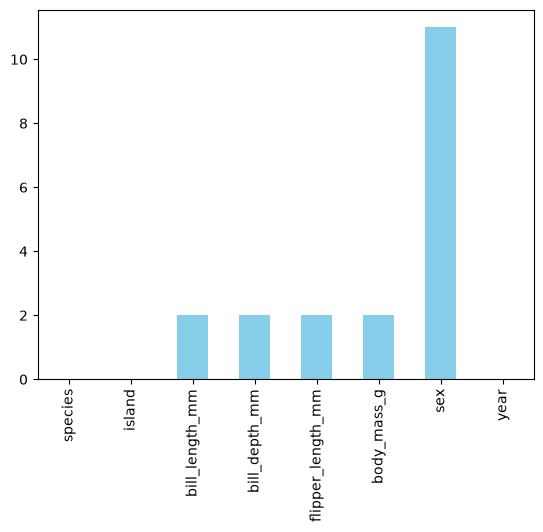

In [17]:
missing_before.plot(kind='bar', color='skyblue')

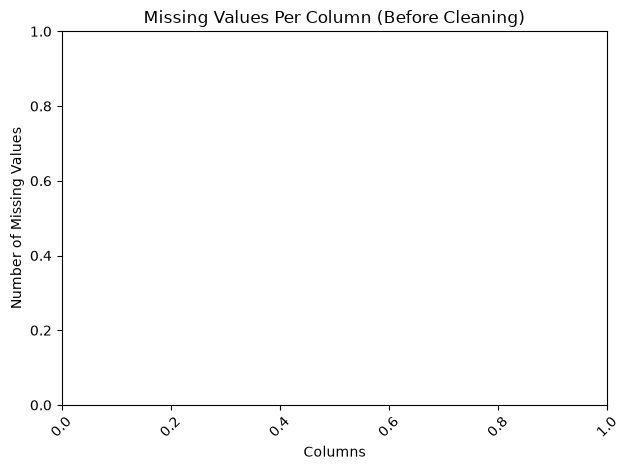

In [18]:
plt.title("Missing Values Per Column (Before Cleaning)")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
# 4. Handle missing numerical values using median
numerical_columns = df.select_dtypes(include=np.number).columns

In [20]:
for column in numerical_columns:
    median_value = df[column].median()
    df[column] = df[column].fillna(median_value)

In [21]:
# 5. Handle missing categorical values using mode
categorical_columns = df.select_dtypes(include=['object', 'str']).columns

In [22]:
for column in categorical_columns:
    mode_value = df[column].mode()[0]
    df[column] = df[column].fillna(mode_value)

In [23]:
# 6. Display missing values after cleaning
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


Missing Values After Cleaning:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
dtype: int64


In [24]:
remaining_missing = df.isnull().sum().sum()

In [25]:
print("\nTotal Missing Values After Cleaning:", remaining_missing)


Total Missing Values After Cleaning: 0


In [26]:
print("\nMissing Values Handling Completed!")


Missing Values Handling Completed!


==========================================
Task 3: Identify and Remove Duplicate Records
==========================================

In [27]:
print("\n\n========== TASK 3: DUPLICATE RECORDS ==========")



========== TASK 3: DUPLICATE RECORDS ==========


In [28]:
# 1. Identify duplicate rows
duplicates = df.duplicated()

In [29]:
# 2. Count duplicate rows before removal
duplicates_before = duplicates.sum()

In [30]:
print("\nDuplicate Records Before Removal:")
print("Total Duplicate Rows:", duplicates_before)


Duplicate Records Before Removal:
Total Duplicate Rows: 0


In [31]:
# 3. Remove duplicate rows if they exist
if duplicates_before > 0:
    df.drop_duplicates(inplace=True)
    print("\nDuplicate records have been removed.")
else:
    print("\nNo duplicate records found. No rows were removed.")


No duplicate records found. No rows were removed.


In [32]:
# 4. Verify duplicate removal
duplicates_after = df.duplicated().sum()

In [33]:
print("\nDuplicate Records After Removal:")
print("Total Duplicate Rows:", duplicates_after)


Duplicate Records After Removal:
Total Duplicate Rows: 0


In [34]:
# Display updated dataset shape
print("\nUpdated Dataset Shape:")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])


Updated Dataset Shape:
Number of Rows: 344
Number of Columns: 8


In [35]:
print("\nDuplicate Records Check Completed!")


Duplicate Records Check Completed!


==========================================
Task 4: Handle Inconsistent Categorical Data
==========================================

In [36]:
print("\n\n========== TASK 4: INCONSISTENT CATEGORICAL DATA ==========")



========== TASK 4: INCONSISTENT CATEGORICAL DATA ==========


In [37]:
# 1. List all categorical columns
categorical_columns = df.select_dtypes(include=['object', 'str']).columns

In [38]:
print("\nCategorical Columns:")
print(list(categorical_columns))


Categorical Columns:
['species', 'island', 'sex']


In [39]:
# 2. Display unique values before standardization
print("\nUnique Values Before Standardization:")


Unique Values Before Standardization:


In [40]:
for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


species:
<StringArray>
['Adelie', 'Gentoo', 'Chinstrap']
Length: 3, dtype: str

island:
<StringArray>
['Torgersen', 'Biscoe', 'Dream']
Length: 3, dtype: str

sex:
<StringArray>
['male', 'female']
Length: 2, dtype: str


In [41]:
# 3. Check extra spaces and inconsistent capitalization
print("\nChecking Extra Spaces and Capitalization:")


Checking Extra Spaces and Capitalization:


In [42]:
for column in categorical_columns:
    values = df[column].dropna()

    extra_spaces = values.apply(
        lambda x: x != x.strip()
    ).sum()

    mixed_case = values.apply(
        lambda x: x != x.lower()
    ).sum()

    print(f"\nColumn: {column}")
    print("Values with extra spaces:", extra_spaces)
    print("Values with uppercase characters:", mixed_case)


Column: species
Values with extra spaces: 0
Values with uppercase characters: 344

Column: island
Values with extra spaces: 0
Values with uppercase characters: 344

Column: sex
Values with extra spaces: 0
Values with uppercase characters: 0


In [43]:
# 4. Standardize categorical values
for column in categorical_columns:
    df[column] = df[column].str.strip().str.lower()

In [44]:
# 5. Display unique values after standardization
print("\nUnique Values After Standardization:")


Unique Values After Standardization:


In [45]:
for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


species:
<StringArray>
['adelie', 'gentoo', 'chinstrap']
Length: 3, dtype: str

island:
<StringArray>
['torgersen', 'biscoe', 'dream']
Length: 3, dtype: str

sex:
<StringArray>
['male', 'female']
Length: 2, dtype: str


In [46]:
print("\nCategorical Data Standardization Completed!")


Categorical Data Standardization Completed!


==========================================
Task 5: Detect and Handle Outliers
==========================================

In [47]:
print("\n\n========== TASK 5: DETECT AND HANDLE OUTLIERS ==========")



========== TASK 5: DETECT AND HANDLE OUTLIERS ==========


In [48]:
# 1. Select two numerical columns
selected_columns = ['bill_length_mm', 'body_mass_g']

In [49]:
# 2. Generate boxplots
plt.figure(figsize=(12, 5))

<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

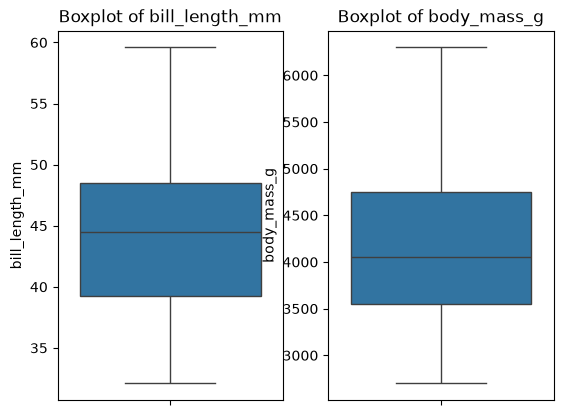

In [50]:
for i, column in enumerate(selected_columns):
    plt.subplot(1, 2, i + 1)
    sns.boxplot(y=df[column])
    plt.title(f"Boxplot of {column}")
    plt.ylabel(column)

In [51]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [52]:
# 3. Calculate IQR and identify outliers
for column in selected_columns:

    print(f"\n========== {column} ==========")

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    print("Q1:", round(Q1, 2))
    print("Q3:", round(Q3, 2))
    print("IQR:", round(IQR, 2))
    print("Lower Bound:", round(lower_bound, 2))
    print("Upper Bound:", round(upper_bound, 2))

    # 4. Identify values outside the bounds
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print("\nNumber of Outliers:", len(outliers))
    print("Outlier Values:")
    print(outliers[column].tolist())

    # Display records for investigation
    print("\nOutlier Records:")
    print(outliers[['species', 'island', column, 'sex']])

    # 5. Decide how to handle outliers
    print("\nDecision: Retain the identified outliers.")
    print("Reason: These are biological measurements.")
    print("Unusual values may represent genuine differences")
    print("between penguins, not necessarily data errors.")


========== bill_length_mm ==========
Q1: 39.28
Q3: 48.5
IQR: 9.23
Lower Bound: 25.44
Upper Bound: 62.34

Number of Outliers: 0
Outlier Values:
[]

Outlier Records:
Empty DataFrame
Columns: [species, island, bill_length_mm, sex]
Index: []

Decision: Retain the identified outliers.
Reason: These are biological measurements.
Unusual values may represent genuine differences
between penguins, not necessarily data errors.

========== body_mass_g ==========
Q1: 3550.0
Q3: 4750.0
IQR: 1200.0
Lower Bound: 1750.0
Upper Bound: 6550.0

Number of Outliers: 0
Outlier Values:
[]

Outlier Records:
Empty DataFrame
Columns: [species, island, body_mass_g, sex]
Index: []

Decision: Retain the identified outliers.
Reason: These are biological measurements.
Unusual values may represent genuine differences
between penguins, not necessarily data errors.


In [53]:
print("\nOutlier Detection and Investigation Completed!")


Outlier Detection and Investigation Completed!


==========================================
Task 6: Data Visualization
==========================================

In [54]:
print("\n\n========== TASK 6: DATA VISUALIZATION ==========")



========== TASK 6: DATA VISUALIZATION ==========


In [55]:
# 1. Histogram - Distribution of Bill Length
plt.figure(figsize=(8, 5))

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Axes: xlabel='bill_length_mm', ylabel='Count'>

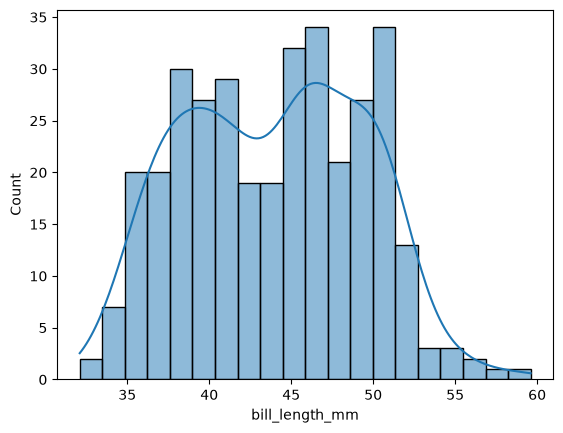

In [56]:
sns.histplot(data=df, x='bill_length_mm', bins=20, kde=True)

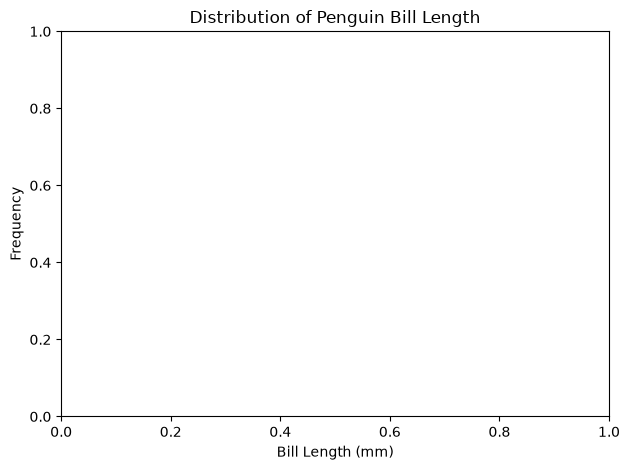

In [57]:
plt.title("Distribution of Penguin Bill Length")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [58]:
# 2. Bar Chart - Frequency of Penguin Species
plt.figure(figsize=(8, 5))

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Axes: xlabel='species', ylabel='count'>

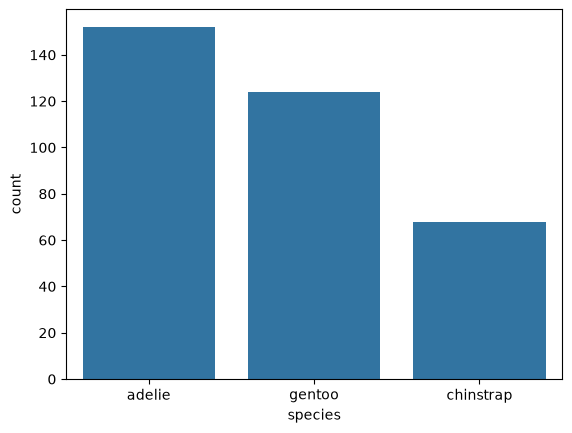

In [59]:
sns.countplot(data=df, x='species', order=df['species'].value_counts().index)

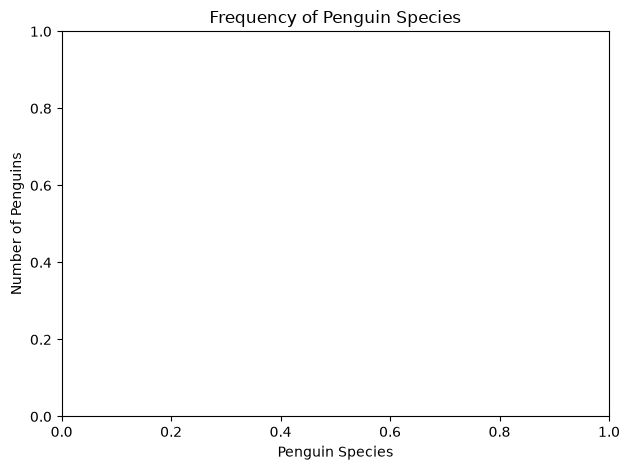

In [60]:
plt.title("Frequency of Penguin Species")
plt.xlabel("Penguin Species")
plt.ylabel("Number of Penguins")
plt.tight_layout()
plt.show()

In [61]:
print("\nSpecies Frequency:")
print(df['species'].value_counts())


Species Frequency:
species
adelie       152
gentoo       124
chinstrap     68
Name: count, dtype: int64


In [62]:
# 3. Boxplot - Distribution of Body Mass
plt.figure(figsize=(8, 5))

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Axes: ylabel='body_mass_g'>

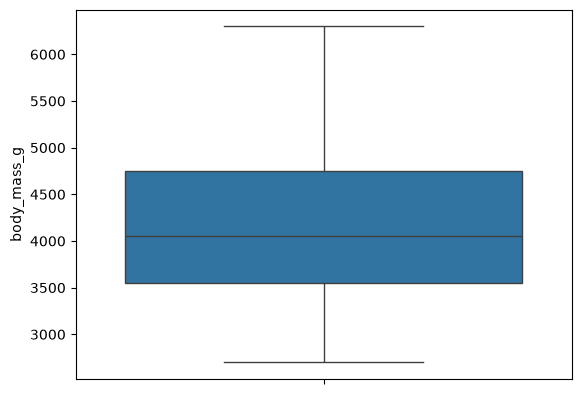

In [63]:
sns.boxplot(data=df, y='body_mass_g')

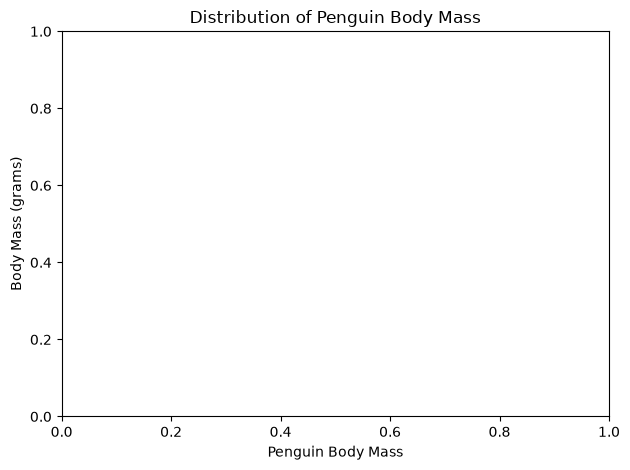

In [64]:
plt.title("Distribution of Penguin Body Mass")
plt.xlabel("Penguin Body Mass")
plt.ylabel("Body Mass (grams)")
plt.tight_layout()
plt.show()

In [65]:
# 4. Heatmap - Correlation Between Numerical Features
numerical_data = df.select_dtypes(include=np.number)

In [66]:
correlation_matrix = numerical_data.corr()

In [67]:
plt.figure(figsize=(10, 7))

<Figure size 1000x700 with 0 Axes>

<Figure size 1000x700 with 0 Axes>

<Axes: >

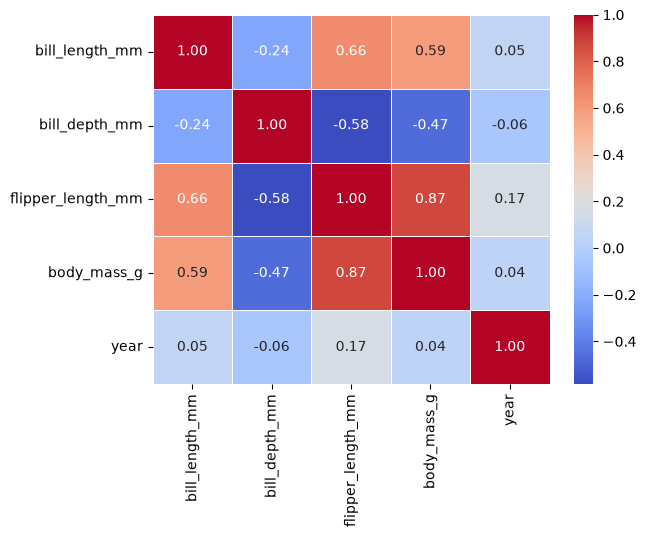

In [68]:
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

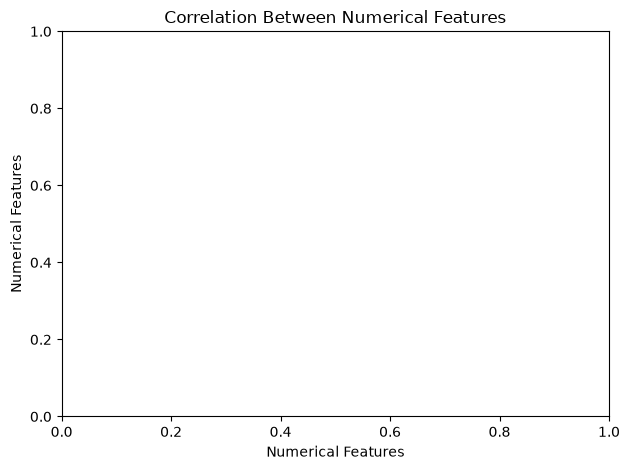

In [69]:
plt.title("Correlation Between Numerical Features")
plt.xlabel("Numerical Features")
plt.ylabel("Numerical Features")
plt.tight_layout()
plt.show()

In [70]:
print("\nCorrelation Matrix:")
print(correlation_matrix)


Correlation Matrix:
                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm           1.000000      -0.235000           0.655858   
bill_depth_mm           -0.235000       1.000000          -0.583832   
flipper_length_mm        0.655858      -0.583832           1.000000   
body_mass_g              0.594925      -0.471942           0.871221   
year                     0.054285      -0.060105           0.168954   

                   body_mass_g      year  
bill_length_mm        0.594925  0.054285  
bill_depth_mm        -0.471942 -0.060105  
flipper_length_mm     0.871221  0.168954  
body_mass_g           1.000000  0.042060  
year                  0.042060  1.000000  


In [71]:
print("\nAll Four Visualizations Generated Successfully!")


All Four Visualizations Generated Successfully!


==========================================
Task 7: Feature Engineering
==========================================

In [72]:
print("\n\n========== TASK 7: FEATURE ENGINEERING ==========")



========== TASK 7: FEATURE ENGINEERING ==========


In [73]:
# 1. Create a new feature: Bill Length-to-Depth Ratio
df['bill_length_depth_ratio'] = (
    df['bill_length_mm'] / df['bill_depth_mm']
)

In [74]:
# 2. Display original and new columns
print("\nOriginal and New Features:")


Original and New Features:


In [75]:
print(df[[
    'bill_length_mm',
    'bill_depth_mm',
    'bill_length_depth_ratio'
]].head(10))

   bill_length_mm  bill_depth_mm  bill_length_depth_ratio
0           39.10           18.7                 2.090909
1           39.50           17.4                 2.270115
2           40.30           18.0                 2.238889
3           44.45           17.3                 2.569364
4           36.70           19.3                 1.901554
5           39.30           20.6                 1.907767
6           38.90           17.8                 2.185393
7           39.20           19.6                 2.000000
8           34.10           18.1                 1.883978
9           42.00           20.2                 2.079208


In [76]:
# 3. Display descriptive statistics of the new feature
print("\nNew Feature Statistics:")
print(df['bill_length_depth_ratio'].describe())


New Feature Statistics:
count    344.000000
mean       2.605438
std        0.495930
min        1.639810
25%        2.161882
50%        2.571484
75%        3.097572
max        3.612676
Name: bill_length_depth_ratio, dtype: float64


In [77]:
print("\nNew Feature Created Successfully!")


New Feature Created Successfully!


==========================================
Task 8: Encode Categorical Variables
==========================================

In [78]:
print("\n\n========== TASK 8: ENCODE CATEGORICAL VARIABLES ==========")



========== TASK 8: ENCODE CATEGORICAL VARIABLES ==========


In [79]:
# 1. Identify categorical columns
categorical_columns = df.select_dtypes(include=['object', 'str']).columns

In [80]:
print("\nCategorical Columns:")
print(list(categorical_columns))


Categorical Columns:
['species', 'island', 'sex']


In [81]:
# 2. Display dataset before encoding
print("\nDataset Before Encoding:")
print(df[['species', 'island', 'sex']].head(10))


Dataset Before Encoding:
  species     island     sex
0  adelie  torgersen    male
1  adelie  torgersen  female
2  adelie  torgersen  female
3  adelie  torgersen    male
4  adelie  torgersen  female
5  adelie  torgersen    male
6  adelie  torgersen  female
7  adelie  torgersen    male
8  adelie  torgersen    male
9  adelie  torgersen    male


In [82]:
# Create a separate copy for encoding
encoded_df = df.copy()

In [83]:
# 3. Apply Label Encoding to sex column
sex_mapping = {
    'female': 0,
    'male': 1
}

In [84]:
encoded_df['sex_encoded'] = encoded_df['sex'].map(sex_mapping)

In [85]:
print("\nLabel Encoding Applied to Sex:")
print(encoded_df[['sex', 'sex_encoded']].head(10))


Label Encoding Applied to Sex:
      sex  sex_encoded
0    male            1
1  female            0
2  female            0
3    male            1
4  female            0
5    male            1
6  female            0
7    male            1
8    male            1
9    male            1


In [86]:
# 4. Apply One-Hot Encoding to island column
encoded_df = pd.get_dummies(
    encoded_df,
    columns=['island'],
    prefix='island',
    dtype=int
)

In [87]:
# 5. Display dataset after encoding
print("\nDataset After Encoding:")
print(encoded_df[[
    'species',
    'sex',
    'sex_encoded',
    'island_biscoe',
    'island_dream',
    'island_torgersen'
]].head(10))


Dataset After Encoding:
  species     sex  sex_encoded  island_biscoe  island_dream  island_torgersen
0  adelie    male            1              0             0                 1
1  adelie  female            0              0             0                 1
2  adelie  female            0              0             0                 1
3  adelie    male            1              0             0                 1
4  adelie  female            0              0             0                 1
5  adelie    male            1              0             0                 1
6  adelie  female            0              0             0                 1
7  adelie    male            1              0             0                 1
8  adelie    male            1              0             0                 1
9  adelie    male            1              0             0                 1


In [88]:
# Display new encoded columns
print("\nEncoded Columns:")
print([
    'sex_encoded',
    'island_biscoe',
    'island_dream',
    'island_torgersen'
])


Encoded Columns:
['sex_encoded', 'island_biscoe', 'island_dream', 'island_torgersen']


In [89]:
print("\nCategorical Encoding Completed Successfully!")


Categorical Encoding Completed Successfully!


==========================================
Task 9: Feature Scaling
==========================================

In [90]:
print("\n\n========== TASK 9: FEATURE SCALING ==========")



========== TASK 9: FEATURE SCALING ==========


In [91]:
# 2. Select two numerical features
selected_features = ['bill_length_mm', 'body_mass_g']

In [92]:
# Create a separate DataFrame
scaling_data = df[selected_features].copy()

In [93]:
# 3. Apply Min-Max Scaling
minmax_scaler = MinMaxScaler()

In [94]:
minmax_scaled = minmax_scaler.fit_transform(scaling_data)

In [95]:
minmax_df = pd.DataFrame(
    minmax_scaled,
    columns=['bill_length_minmax', 'body_mass_minmax']
)

In [96]:
# 4. Apply Standardization
standard_scaler = StandardScaler()

In [97]:
standard_scaled = standard_scaler.fit_transform(scaling_data)

In [98]:
standard_df = pd.DataFrame(
    standard_scaled,
    columns=['bill_length_standard', 'body_mass_standard']
)

In [99]:
# 5. Compare original and scaled values
comparison_df = pd.concat(
    [
        scaling_data.reset_index(drop=True),
        minmax_df,
        standard_df
    ],
    axis=1
)

In [100]:
print("\nBefore and After Scaling (First 10 Rows):")
print(comparison_df.head(10).round(3))


Before and After Scaling (First 10 Rows):
   bill_length_mm  body_mass_g  bill_length_minmax  body_mass_minmax  \
0           39.10       3750.0               0.255             0.292   
1           39.50       3800.0               0.269             0.306   
2           40.30       3250.0               0.298             0.153   
3           44.45       4050.0               0.449             0.375   
4           36.70       3450.0               0.167             0.208   
5           39.30       3650.0               0.262             0.264   
6           38.90       3625.0               0.247             0.257   
7           39.20       4675.0               0.258             0.549   
8           34.10       3475.0               0.073             0.215   
9           42.00       4250.0               0.360             0.431   

   bill_length_standard  body_mass_standard  
0                -0.888              -0.565  
1                -0.814              -0.502  
2                -0.667   

In [101]:
# 6. Display descriptive statistics
print("\nMin-Max Scaling Statistics:")
print(minmax_df.describe().round(3))


Min-Max Scaling Statistics:
       bill_length_minmax  body_mass_minmax
count             344.000           344.000
mean                0.430             0.417
std                 0.198             0.222
min                 0.000             0.000
25%                 0.261             0.236
50%                 0.449             0.375
75%                 0.596             0.569
max                 1.000             1.000


In [102]:
print("\nStandardization Statistics:")
print(standard_df.describe().round(3))


Standardization Statistics:
       bill_length_standard  body_mass_standard
count               344.000             344.000
mean                 -0.000               0.000
std                   1.001               1.001
min                  -2.175              -1.880
25%                  -0.855              -0.815
50%                   0.097              -0.189
75%                   0.842               0.688
max                   2.884               2.629


In [103]:
print("\nFeature Scaling Completed Successfully!")


Feature Scaling Completed Successfully!


==========================================
Task 10: Prepare and Save Cleaned Dataset
==========================================

In [104]:
print("\n\n========== TASK 10: FINAL CLEANED DATASET ==========")



========== TASK 10: FINAL CLEANED DATASET ==========


In [105]:
# 1. Verify missing values
print("\nMissing Values in Final Dataset:")
print(df.isnull().sum())


Missing Values in Final Dataset:
species                    0
island                     0
bill_length_mm             0
bill_depth_mm              0
flipper_length_mm          0
body_mass_g                0
sex                        0
year                       0
bill_length_depth_ratio    0
dtype: int64


In [106]:
total_missing = df.isnull().sum().sum()
print("\nTotal Missing Values:", total_missing)


Total Missing Values: 0


In [107]:
# 2. Verify duplicate records
duplicates = df.duplicated().sum()
print("\nTotal Duplicate Records:", duplicates)


Total Duplicate Records: 0


In [108]:
# 3. Display final dataset
print("\nFinal Cleaned Dataset:")
print(df.to_string(index=False))


Final Cleaned Dataset:
  species    island  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g    sex  year  bill_length_depth_ratio
   adelie torgersen           39.10           18.7              181.0       3750.0   male  2007                 2.090909
   adelie torgersen           39.50           17.4              186.0       3800.0 female  2007                 2.270115
   adelie torgersen           40.30           18.0              195.0       3250.0 female  2007                 2.238889
   adelie torgersen           44.45           17.3              197.0       4050.0   male  2007                 2.569364
   adelie torgersen           36.70           19.3              193.0       3450.0 female  2007                 1.901554
   adelie torgersen           39.30           20.6              190.0       3650.0   male  2007                 1.907767
   adelie torgersen           38.90           17.8              181.0       3625.0 female  2007                 2.185393
   adeli

In [109]:
# 4. Display final dataset information
print("\nFinal Dataset Information:")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])


Final Dataset Information:
Total Rows: 344
Total Columns: 9


In [110]:
# 5. Save cleaned dataset as CSV
df.to_csv("penguins_cleaned.csv", index=False)

In [111]:
print("\nCleaned dataset saved successfully as penguins_cleaned.csv")


Cleaned dataset saved successfully as penguins_cleaned.csv


In [112]:
# 6. Final verification
if total_missing == 0 and duplicates == 0:
    print("\nAll cleaning operations completed successfully!")
else:
    print("\nWarning: Some cleaning issues still exist.")


All cleaning operations completed successfully!


# Explanation of All EDA Tasks

## Task 1: Load and Understand the Dataset

**Objective:** Load the Palmer Penguins dataset and understand its structure.

**Explanation:** The dataset was loaded using the Pandas library. The `head()` function was used to display the first five rows, while `shape`, `columns`, and `info()` were used to examine the number of rows, columns, and data types.

**Observation:** The original dataset contains 344 rows and 8 columns.

---

## Task 2: Handle Missing Values

**Objective:** Identify and handle missing values in the dataset.

**Explanation:** The `isnull().sum()` function was used to identify missing values. Numeric missing values were replaced with the median, while categorical missing values were replaced with the mode.

**Observation:** Initially, the dataset contained 19 missing values (approximately 0.69%). After handling them, no missing values remained.

---

## Task 3: Remove Duplicate Records

**Objective:** Identify and remove duplicate records.

**Explanation:** The `duplicated()` function was used to check for duplicate rows. The `drop_duplicates()` function was used to remove duplicates if found.

**Observation:** No duplicate records were found, so no rows were removed.

---

## Task 4: Standardize Categorical Data

**Objective:** Make categorical values consistent.

**Explanation:** Extra spaces were removed using `strip()`, and categorical values were converted into lowercase using `lower()`. This helped maintain consistency in the species, island, and sex columns.

**Observation:** Categorical values were standardized successfully.

---

## Task 5: Detect and Handle Outliers

**Objective:** Identify unusual values in numerical columns.

**Explanation:** The Interquartile Range (IQR) method was used to detect outliers in the `bill_length_mm` and `body_mass_g` columns. The IQR was calculated using the first quartile (Q1) and third quartile (Q3).

**Observation:** No outliers were detected in the selected columns. Therefore, all records were retained.

---

## Task 6: Data Visualization

**Objective:** Understand the dataset through visual representations.

**Explanation:** Different visualizations were created using Matplotlib and Seaborn:
- Histogram to show the distribution of bill length.
- Bar chart to display species frequency.
- Boxplot to examine body mass distribution.
- Correlation heatmap to identify relationships between numerical features.

**Observation:** Adelie was the most frequent species with 152 records, followed by Gentoo (124) and Chinstrap (68). Flipper length and body mass showed a strong positive correlation of approximately 0.87.

---

## Task 7: Feature Engineering

**Objective:** Create a new meaningful feature from existing columns.

**Explanation:** A new feature named `bill_length_depth_ratio` was created by dividing `bill_length_mm` by `bill_depth_mm`.

**Observation:** The new feature provides a ratio between bill length and bill depth, adding useful information for further analysis.

---

## Task 8: Categorical Data Encoding

**Objective:** Convert categorical data into numerical form.

**Explanation:** Label encoding was applied to the sex column, where female was represented by 0 and male by 1. One-Hot Encoding was applied to the island column, creating separate binary columns for each island.

**Observation:** Categorical variables were successfully converted into numerical representations without changing the original dataset.

---

## Task 9: Feature Scaling

**Objective:** Bring numerical features to comparable scales.

**Explanation:** Two scaling techniques were applied to `bill_length_mm` and `body_mass_g`:
- Min-Max Scaling converts values into a range between 0 and 1.
- Standard Scaling transforms values to have a mean of approximately 0 and a standard deviation of approximately 1.

**Observation:** Both scaling methods were successfully applied. The original dataset remained unchanged.

---

## Task 10: Final Cleaned Dataset

**Objective:** Save and verify the final cleaned dataset.

**Explanation:** After completing all preprocessing steps, the cleaned dataset was saved as `penguins_cleaned.csv`. The final dataset was checked for missing values, duplicate records, and its overall structure.

**Observation:** The final cleaned dataset contains 344 rows and 9 columns, with zero missing values and zero duplicate records.

---

# Overall Result

The Palmer Penguins dataset was successfully explored, cleaned, transformed, and visualized using Python. Missing values were handled, categorical data was standardized and encoded, outliers were checked, new features were created, and numerical features were scaled. The final cleaned dataset was saved successfully for further analysis.

# Section 6: Additional Questions

## Q1. Why is data preprocessing important before analysis?

**Answer:** Data preprocessing is important because raw data may contain missing values, duplicate records, inconsistent categories, and outliers. Cleaning the data improves its quality, reliability, and accuracy, making it suitable for further analysis.

## Q2. What is the difference between missing values and duplicate records?

**Answer:** Missing values are entries where information has not been recorded, whereas duplicate records are repeated rows containing the same information. Missing values can be handled through imputation or removal, while duplicate records can be identified and removed when appropriate.

## Q3. Why is the median preferred over the mean when handling missing numerical values?

**Answer:** The median is less affected by extreme values and outliers than the mean. Therefore, it is often a better choice for filling missing numerical values, especially when the data is skewed.

## Q4. What are outliers, and should they always be removed?

**Answer:** Outliers are unusually high or low values compared to the rest of the data. They should not always be removed because they may represent genuine observations or natural variation. They should first be investigated before deciding whether to remove them.

## Q5. What is the difference between Label Encoding and One-Hot Encoding?

**Answer:** Label Encoding converts categories into numerical values, such as female = 0 and male = 1. One-Hot Encoding creates separate binary columns for each category. Label Encoding is useful for binary categories, while One-Hot Encoding is suitable for nominal categories such as island names.

## Q6. Why is feature scaling important in data preprocessing?

**Answer:** Feature scaling brings numerical features to comparable ranges. Without scaling, features with larger numerical ranges may dominate certain algorithms. It is particularly useful for algorithms such as K-Nearest Neighbors (KNN), Support Vector Machines (SVM), and gradient-based methods. Min-Max Scaling and Standard Scaling are two common techniques.

## Q7. What problems can occur if uncleaned data is used for analysis?

**Answer:** Uncleaned data can produce misleading results because missing values may cause errors, duplicate records may create biased counts, inconsistent categories may lead to incorrect grouping, and outliers may affect statistical calculations. Unscaled features may also negatively affect some machine learning algorithms.

---

# Section 6 Summary

Data preprocessing helps improve data quality and makes analysis more reliable. Different preprocessing techniques are selected according to the type and characteristics of the dataset.

# Conclusion

The Exploratory Data Analysis (EDA) of the Palmer Penguins dataset was successfully performed using Python. The original dataset contained 344 rows and 8 columns.

During preprocessing, 19 missing values (approximately 0.69%) were identified. Numeric missing values were handled using the median, while categorical missing values were replaced with the mode. No duplicate records were found. Categorical values were also standardized to maintain consistency.

The IQR method was used to detect outliers in selected numerical columns, but no outliers were detected. Different visualizations, including histograms, bar charts, boxplots, and a correlation heatmap, were created to understand the dataset. The analysis showed that Adelie was the most frequent species, with 152 records. A strong positive correlation of approximately 0.87 was also observed between flipper length and body mass.

Feature engineering was performed by creating a new feature called `bill_length_depth_ratio`. Categorical variables were converted into numerical form using Label Encoding and One-Hot Encoding. Min-Max Scaling and Standard Scaling were also applied to selected numerical features.

Finally, the cleaned dataset was saved as `penguins_cleaned.csv`. It contains 344 rows and 9 columns, with no missing values or duplicate records.

**Overall, this assignment provided practical experience in data loading, cleaning, preprocessing, visualization, feature engineering, encoding, and scaling using Python libraries. These techniques are important for preparing reliable datasets for further data analysis and machine learning applications.**